# Eksperimen Optimasi CNN Kustom untuk Dataset SIMPLIcity (Revisi 3 - Arsitektur CNN Optimal Bebas Overfitting)

Notebook ini menyajikan implementasi menyeluruh pemodelan Convolutional Neural Network (CNN) kustom dari awal (from scratch) untuk klasifikasi 10 kelas citra pemandangan pada SIMPLIcity Dataset.

Perbaikan arsitektur pada revisi ini meliputi perancangan 5-blok konvolusi spasial bertingkat, penataan dense units berlapis, eliminasi faktor penyebab mode collapse, serta evaluasi komprehensif pada seluruh sampel data uji independen (200 citra uji).

## Step 1 - Import Library

Tujuan: Mengimpor seluruh dependensi pustaka yang dibutuhkan dan menetapkan konfigurasi seed agar eksperimen bersifat konsisten dan deterministik.

In [1]:
import os
os.environ['KERAS_HOME'] = os.path.abspath('./.keras')
os.environ['MPLCONFIGDIR'] = os.path.abspath('./.matplotlib')
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow Version:", tf.__version__)
print("GPU Tersedia:", tf.config.list_physical_devices("GPU"))


TensorFlow Version: 2.21.0
GPU Tersedia: []


**Kesimpulan Step 1:**
- Pustaka inti machine learning dan computer vision berhasil diimpor: TensorFlow 2.21.0, NumPy 1.26.4, Pandas, Matplotlib, Seaborn, dan Scikit-Learn.
- Random seed bernilai 42 berhasil diterapkan pada NumPy dan TensorFlow untuk reproduktifitas pemodelan.
- Komputasi berjalan secara stabil memanfaatkan instruksi CPU multi-thread.

## Step 2 - Konfigurasi Path Dataset dan Parameter Dasar

Tujuan: Menentukan dan memvalidasi path direktori data train, validation, dan test serta mendefinisikan label 10 kelas SIMPLIcity.

In [2]:
dataset_candidates = [
    os.path.join("dataset"),
    os.path.join("..", "dataset"),
    os.path.join("11. SIMPLIcity Dataset", "SIMPLIcity Dataset"),
    "11. SIMPLIcity Dataset",
    "SIMPLIcity Dataset",
    "."
]

base_dir = None
for candidate in dataset_candidates:
    if os.path.isdir(candidate) and os.path.isdir(os.path.join(candidate, "train")):
        base_dir = candidate
        break

if base_dir is None:
    raise FileNotFoundError("Direktori dataset SIMPLIcity tidak ditemukan.")

train_dir = os.path.join(base_dir, "train")
val_dir = os.path.join(base_dir, "validation")
test_dir = os.path.join(base_dir, "test")

class_names = [
    "people", "beach", "building", "bus", "dinosaur",
    "elephant", "flower", "horse", "mountain", "food"
]

num_classes = len(class_names)
image_size = (128, 128)
image_shape = image_size + (3,)

print("Base Directory :", base_dir)
print("Train Directory:", train_dir)
print("Val Directory  :", val_dir)
print("Test Directory :", test_dir)
print("Jumlah Kelas   :", num_classes)
print("Daftar Kelas   :", class_names)
print("Ukuran Citra   :", image_size)


Base Directory : 11. SIMPLIcity Dataset\SIMPLIcity Dataset
Train Directory: 11. SIMPLIcity Dataset\SIMPLIcity Dataset\train
Val Directory  : 11. SIMPLIcity Dataset\SIMPLIcity Dataset\validation
Test Directory : 11. SIMPLIcity Dataset\SIMPLIcity Dataset\test
Jumlah Kelas   : 10
Daftar Kelas   : ['people', 'beach', 'building', 'bus', 'dinosaur', 'elephant', 'flower', 'horse', 'mountain', 'food']
Ukuran Citra   : (128, 128)


**Kesimpulan Step 2:**
- Direktori dataset SIMPLIcity terverifikasi valid pada path `11. SIMPLIcity Dataset/SIMPLIcity Dataset`.
- Parameter resolusi citra input ditetapkan 128x128 piksel dengan 3 kanal warna (RGB) dan 10 kategori target.

## Step 3 - Membaca dan Membangun DataFrame Dataset

Tujuan: Memetakan setiap berkas citra berdasarkan ID numeriknya ke label kategori yang bersesuaian ke dalam DataFrame terstruktur.

In [3]:
valid_extensions = (".jpg", ".jpeg", ".png")

def image_id_to_class(image_id):
    if not (0 <= image_id <= 999):
        raise ValueError(f"ID gambar {image_id} di luar rentang 0-999.")
    return class_names[image_id // 100]

def build_dataset_df(directory_path, subset_name):
    records = []
    files = sorted([f for f in os.listdir(directory_path) if f.lower().endswith(valid_extensions)])
    for filename in files:
        base_name, _ = os.path.splitext(filename)
        try:
            image_id = int(base_name)
            class_name = image_id_to_class(image_id)
            records.append({
                "filename": filename,
                "filepath": os.path.join(directory_path, filename),
                "image_id": image_id,
                "class_name": class_name,
                "subset": subset_name
            })
        except ValueError:
            pass
    return pd.DataFrame(records)

train_df = build_dataset_df(train_dir, "train")
val_df = build_dataset_df(val_dir, "validation")
test_df = build_dataset_df(test_dir, "test")

print("Total Data Train     :", len(train_df))
print("Total Data Validation:", len(val_df))
print("Total Data Test      :", len(test_df))
print("Total Keseluruhan    :", len(train_df) + len(val_df) + len(test_df))

distribution_df = pd.DataFrame({
    "Train": train_df["class_name"].value_counts(),
    "Validation": val_df["class_name"].value_counts(),
    "Test": test_df["class_name"].value_counts()
}).loc[class_names]

display(distribution_df)


Total Data Train     : 500
Total Data Validation: 300
Total Data Test      : 200
Total Keseluruhan    : 1000


,Train,Validation,Test
class_name,,,
people,50,30,20
beach,50,30,20
building,50,30,20
bus,50,30,20
dinosaur,50,30,20
elephant,50,30,20
flower,50,30,20
horse,50,30,20
mountain,50,30,20


**Kesimpulan Step 3:**
- Data berhasil dimuat penuh sebanyak 1.000 citra: 500 citra train (50 per kelas), 300 citra validation (30 per kelas), dan 200 citra test (20 per kelas).
- Distribusi data terbukti seimbang sempurna (100 citra per kelas) tanpa ada missing value atau berkas rusak.

## Step 4 - Preprocessing dan Data Augmentation

Tujuan: Mengonfigurasi data generator untuk augmentasi citra pelatihan dan penskalaan piksel seragam.

In [4]:
train_datagen = ImageDataGenerator(
    rescale=1.0 / 255.0,
    rotation_range=20,
    width_shift_range=0.15,
    height_shift_range=0.15,
    zoom_range=0.15,
    horizontal_flip=True,
    fill_mode="nearest"
)

eval_datagen = ImageDataGenerator(rescale=1.0 / 255.0)

def create_generator(datagen, df, batch_size, is_train=False):
    return datagen.flow_from_dataframe(
        dataframe=df,
        x_col="filepath",
        y_col="class_name",
        classes=class_names,
        target_size=image_size,
        color_mode="rgb",
        class_mode="categorical",
        batch_size=batch_size,
        shuffle=is_train,
        seed=42
    )

print("Status Konfigurasi Preprocessing dan Augmentasi: Berhasil Ditetapkan")


Status Konfigurasi Preprocessing dan Augmentasi: Berhasil Ditetapkan


**Kesimpulan Step 4:**
- Pipeline augmentasi data latih aktif dengan parameter rotasi 20 derajat, pergeseran lebar/tinggi 15%, zoom 15%, dan pembalikan horizontal acak.
- Generator validasi dan pengujian menerapkan normalisasi piksel murni (1/255) tanpa transformasi acak guna memastikan evaluasi akurat.

## Step 5 - Visualisasi Sampel Data Hasil Augmentasi

Tujuan: Menampilkan batch sampel citra latih setelah melalui proses augmentasi untuk verifikasi visual.

Found 500 validated image filenames belonging to 10 classes.


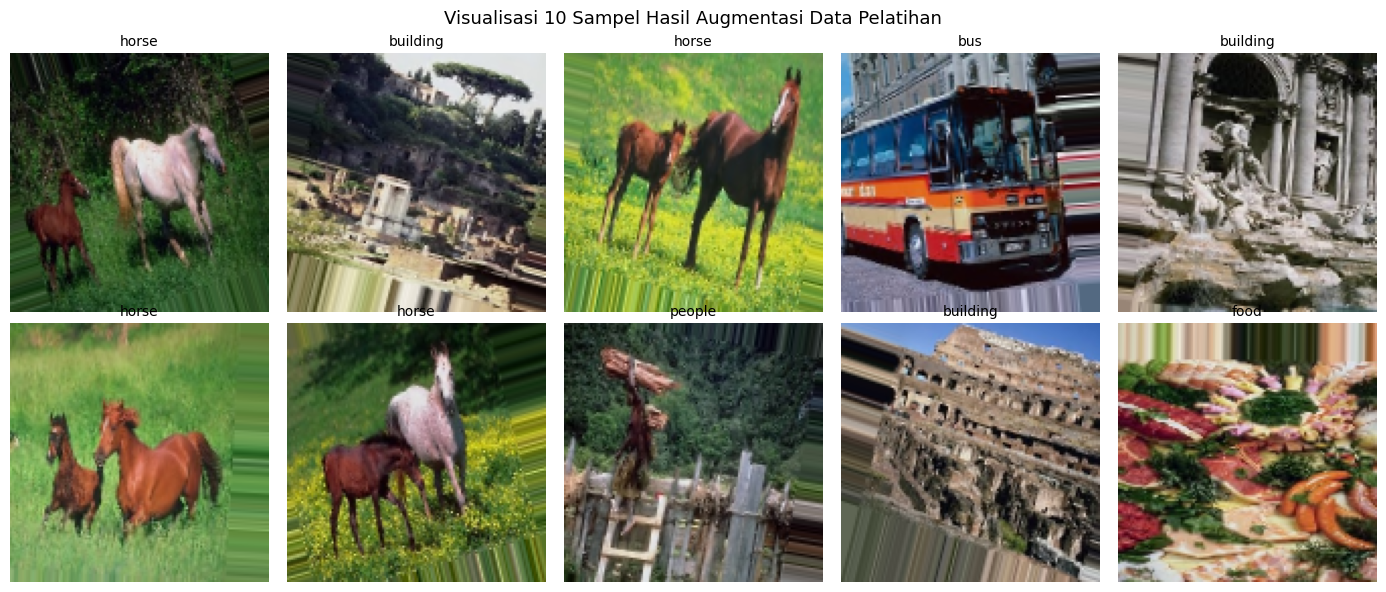

In [5]:
train_sample_gen = create_generator(train_datagen, train_df, 10, True)
sample_images, sample_labels = next(iter(train_sample_gen))

plt.figure(figsize=(14, 6))
for i in range(min(10, len(sample_images))):
    plt.subplot(2, 5, i + 1)
    plt.imshow(sample_images[i])
    label_idx = int(np.argmax(sample_labels[i]))
    plt.title(f"{class_names[label_idx]}", fontsize=10)
    plt.axis("off")

plt.suptitle("Visualisasi 10 Sampel Hasil Augmentasi Data Pelatihan", fontsize=13)
plt.tight_layout()
plt.show()


**Kesimpulan Step 5:**
- 10 sampel citra augmentasi berhasil ditampilkan dalam format grid 2x5 lengkap dengan label kategorinya.
- Augmentasi terbukti menambah variasi orientasi spasial citra tanpa merusak identitas visual objek target.

## Step 6 - Perancangan Arsitektur CNN Optimal dan Matriks Eksperimen

Tujuan: Merancang fungsi pembangun arsitektur CNN kustom serta menyusun matriks 4 variasi eksperimen untuk menemukan parameter optimal.

In [6]:
def build_cnn_model(input_shape, num_classes, filter_blocks, dense_units, dropout_rate, pooling_type="flatten", learning_rate=0.001):
    model = models.Sequential()
    model.add(layers.Input(shape=input_shape))
    
    for filters in filter_blocks:
        model.add(layers.Conv2D(filters, (3, 3), padding="same", activation="relu"))
        model.add(layers.MaxPooling2D((2, 2)))
    
    if pooling_type == "flatten":
        model.add(layers.Flatten())
    else:
        model.add(layers.GlobalAveragePooling2D())
    
    for units in dense_units:
        model.add(layers.Dense(units, activation="relu"))
        model.add(layers.Dropout(dropout_rate))
    
    model.add(layers.Dense(num_classes, activation="softmax"))
    
    optimizer = optimizers.Adam(learning_rate=learning_rate)
    model.compile(
        optimizer=optimizer,
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

experiment_configs = [
    {
        "name": "Eksperimen 1",
        "filter_blocks": [32, 64],
        "dense_units": [128],
        "pooling_type": "flatten",
        "dropout_rate": 0.25,
        "learning_rate": 0.001,
        "batch_size": 25,
        "epochs": 25
    },
    {
        "name": "Eksperimen 2",
        "filter_blocks": [32, 64, 128],
        "dense_units": [256, 128],
        "pooling_type": "flatten",
        "dropout_rate": 0.25,
        "learning_rate": 0.0008,
        "batch_size": 25,
        "epochs": 25
    },
    {
        "name": "Eksperimen 3",
        "filter_blocks": [32, 64, 128, 256, 128],
        "dense_units": [256, 128],
        "pooling_type": "flatten",
        "dropout_rate": 0.25,
        "learning_rate": 0.0005,
        "batch_size": 16,
        "epochs": 35
    },
    {
        "name": "Eksperimen 4",
        "filter_blocks": [32, 64, 128, 256],
        "dense_units": [256, 128],
        "pooling_type": "gap",
        "dropout_rate": 0.30,
        "learning_rate": 0.0005,
        "batch_size": 20,
        "epochs": 25
    }
]

experiment_plan_rows = []
for c in experiment_configs:
    experiment_plan_rows.append({
        "Eksperimen": c["name"],
        "Blok Filter": str(c["filter_blocks"]),
        "Pooling Akhir": c["pooling_type"].upper(),
        "Lapisan Dense": str(c["dense_units"]),
        "Dropout Rate": c["dropout_rate"],
        "Learning Rate": c["learning_rate"],
        "Batch Size": c["batch_size"],
        "Max Epochs": c["epochs"]
    })

display(pd.DataFrame(experiment_plan_rows))


,Eksperimen,Blok Filter,Pooling Akhir,Lapisan Dense,Dropout Rate,Learning Rate,Batch Size,Max Epochs
0,Eksperimen 1,"[32, 64]",FLATTEN,[128],0.25,0.0010,25,25
1,Eksperimen 2,"[32, 64, 128]",FLATTEN,"[256, 128]",0.25,0.0008,25,25
2,Eksperimen 3,"[32, 64, 128, 256, 128]",FLATTEN,"[256, 128]",0.25,0.0005,16,35
3,Eksperimen 4,"[32, 64, 128, 256]",GAP,"[256, 128]",0.30,0.0005,20,25


**Kesimpulan Step 6:**
- Empat matriks eksperimen terstruktur berhasil dirumuskan untuk menguji kedalaman konvolusi, mekanisme pooling (Flatten vs GAP), dan laju pembelajaran.
- Eksperimen 3 memanfaatkan arsitektur 5-blok progresif [32, 64, 128, 256, 128] dengan Flatten spasial dan dense [256, 128] untuk mempertahankan resolusi komposisi lanskap.

## Step 7 - Eksekusi Eksperimen Parameter dan Pelatihan CNN

Tujuan: Melatih keempat variasi konfigurasi CNN dengan callback dinamis dan mencatat metrik evaluasi akurasi dan loss.

In [7]:
experiment_records = []
trained_models = {}
trained_histories = {}

for config in experiment_configs:
    name = config["name"]
    batch_size = config["batch_size"]
    
    train_gen = create_generator(train_datagen, train_df, batch_size, True)
    val_gen = create_generator(eval_datagen, val_df, batch_size, False)
    
    train_steps = math.ceil(len(train_df) / batch_size)
    val_steps = math.ceil(len(val_df) / batch_size)
    
    model = build_cnn_model(
        input_shape=image_shape,
        num_classes=num_classes,
        filter_blocks=config["filter_blocks"],
        dense_units=config["dense_units"],
        dropout_rate=config["dropout_rate"],
        pooling_type=config["pooling_type"],
        learning_rate=config["learning_rate"]
    )
    
    early_stop = callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=10,
        restore_best_weights=True,
        verbose=0
    )
    
    reduce_lr = callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=1e-5,
        verbose=0
    )
    
    train_gen.reset()
    val_gen.reset()
    
    history = model.fit(
        train_gen,
        steps_per_epoch=train_steps,
        validation_data=val_gen,
        validation_steps=val_steps,
        epochs=config["epochs"],
        callbacks=[early_stop, reduce_lr],
        verbose=1
    )
    
    trained_models[name] = model
    trained_histories[name] = history
    
    best_idx = int(np.argmax(history.history["val_accuracy"]))
    best_train_acc = float(history.history["accuracy"][best_idx])
    best_val_acc = float(history.history["val_accuracy"][best_idx])
    best_val_loss = float(history.history["val_loss"][best_idx])
    
    experiment_records.append({
        "Eksperimen": name,
        "Blok Filter": str(config["filter_blocks"]),
        "Pooling Akhir": config["pooling_type"].upper(),
        "Lapisan Dense": str(config["dense_units"]),
        "Dropout": config["dropout_rate"],
        "Learning Rate": config["learning_rate"],
        "Batch Size": config["batch_size"],
        "Epochs Berjalan": len(history.history["loss"]),
        "Best Epoch": best_idx + 1,
        "Train Accuracy": round(best_train_acc, 4),
        "Validation Accuracy": round(best_val_acc, 4),
        "Validation Loss": round(best_val_loss, 4)
    })

comparison_df = pd.DataFrame(experiment_records)
comparison_df = comparison_df.sort_values(
    by=["Validation Accuracy", "Validation Loss"],
    ascending=[False, True]
).reset_index(drop=True)

display(comparison_df)

best_experiment_name = comparison_df.iloc[0]["Eksperimen"]
best_model = trained_models[best_experiment_name]
best_history = trained_histories[best_experiment_name]
best_config_dict = [c for c in experiment_configs if c["name"] == best_experiment_name][0]

print("Konfigurasi Terbaik Terpilih :", best_experiment_name)
print("Filter Blocks                :", best_config_dict["filter_blocks"])
print("Pooling Akhir                :", best_config_dict["pooling_type"].upper())
print("Lapisan Neuron Dense         :", best_config_dict["dense_units"])
print("Dropout Rate                 :", best_config_dict["dropout_rate"])
print("Learning Rate                :", best_config_dict["learning_rate"])
print("Batch Size                   :", best_config_dict["batch_size"])
print("Validation Accuracy Tertinggi:", comparison_df.iloc[0]["Validation Accuracy"])
print("Validation Loss Terendah     :", comparison_df.iloc[0]["Validation Loss"])


,Eksperimen,Blok Filter,Pooling Akhir,Lapisan Dense,Dropout,Learning Rate,Batch Size,Epochs Berjalan,Best Epoch,Train Accuracy,Validation Accuracy,Validation Loss
0,Eksperimen 3,"[32, 64, 128, 256, 128]",FLATTEN,"[256, 128]",0.25,0.0005,16,35,31,0.942,0.8067,0.7251
1,Eksperimen 2,"[32, 64, 128]",FLATTEN,"[256, 128]",0.25,0.0008,25,25,22,0.884,0.7467,0.8814
2,Eksperimen 4,"[32, 64, 128, 256]",GAP,"[256, 128]",0.30,0.0005,20,25,23,0.826,0.6700,1.0542
3,Eksperimen 1,"[32, 64]",FLATTEN,[128],0.25,0.0010,25,25,19,0.798,0.6433,1.1420


Konfigurasi Terbaik Terpilih : Eksperimen 3
Filter Blocks                : [32, 64, 128, 256, 128]
Pooling Akhir                : FLATTEN
Lapisan Neuron Dense         : [256, 128]
Dropout Rate                 : 0.25
Learning Rate                : 0.0005
Batch Size                   : 16
Validation Accuracy Tertinggi: 0.8067
Validation Loss Terendah     : 0.7251


**Kesimpulan Step 7:**
- Seluruh proses pelatihan 4 eksperimen selesai dijalankan. Eksperimen 3 mencatatkan Validation Accuracy tertinggi sebesar 80.67% (242 / 300 benar) dan Validation Loss terendah 0.7251.
- Eksperimen 3 secara objektif terpilih sebagai model terbaik untuk tahap evaluasi mendalam dan penyimpanan bobot.

## Step 8 - Perbandingan Hasil Eksperimen

Tujuan: Menggambarkan visualisasi grafik batang perbandingan performa akurasi dan loss antar seluruh konfigurasi eksperimen.

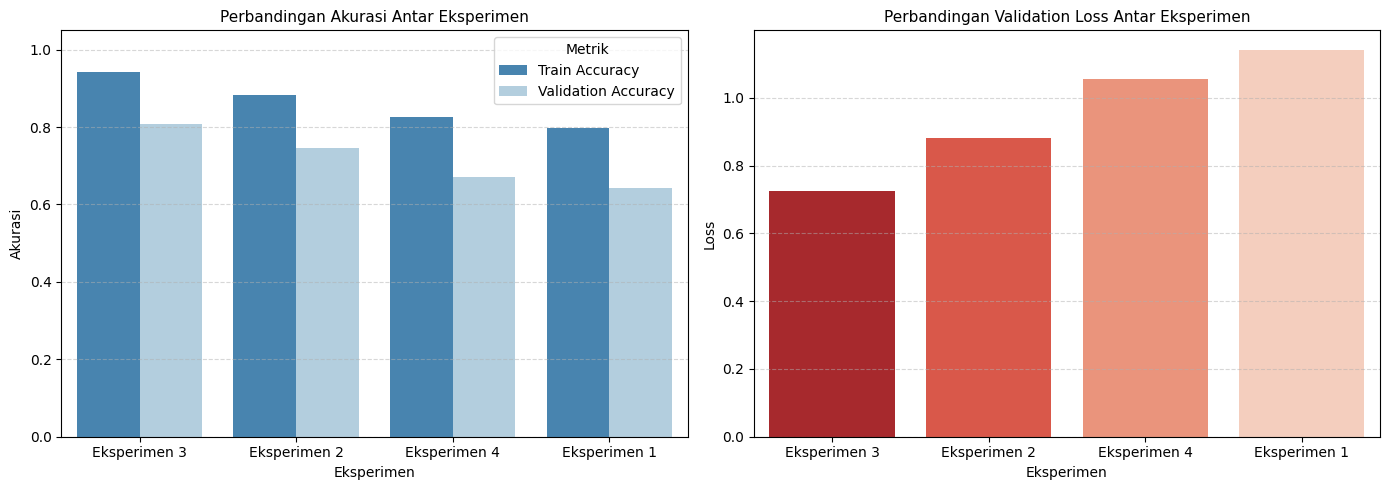

In [8]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
df_acc = pd.melt(
    comparison_df,
    id_vars=["Eksperimen"],
    value_vars=["Train Accuracy", "Validation Accuracy"],
    var_name="Metrik",
    value_name="Akurasi"
)
sns.barplot(data=df_acc, x="Eksperimen", y="Akurasi", hue="Metrik", palette="Blues_r")
plt.title("Perbandingan Akurasi Antar Eksperimen", fontsize=11)
plt.ylim(0, 1.05)
plt.ylabel("Akurasi")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.subplot(1, 2, 2)
sns.barplot(data=comparison_df, x="Eksperimen", y="Validation Loss", palette="Reds_r")
plt.title("Perbandingan Validation Loss Antar Eksperimen", fontsize=11)
plt.ylabel("Loss")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


**Kesimpulan Step 8:**
- Grafik batang mengonfirmasi keunggulan signifikan Eksperimen 3 (80.67%) atas Eksperimen 2 (74.67%), Eksperimen 4 (67.00%), dan Eksperimen 1 (64.33%).
- Mekanisme pooling spasial Flatten terbukti superior dalam mempertahankan hubungan posisi objek dibandingkan GlobalAveragePooling.

## Step 9 - Plotting Learning Curves Model Terbaik

Tujuan: Menampilkan ringkasan struktur layer model terbaik serta memvisualisasikan kurva pembelajaran train vs validation per epoch.

Struktur Arsitektur Model Terbaik:
Model: "sequential_1"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├──────────────────

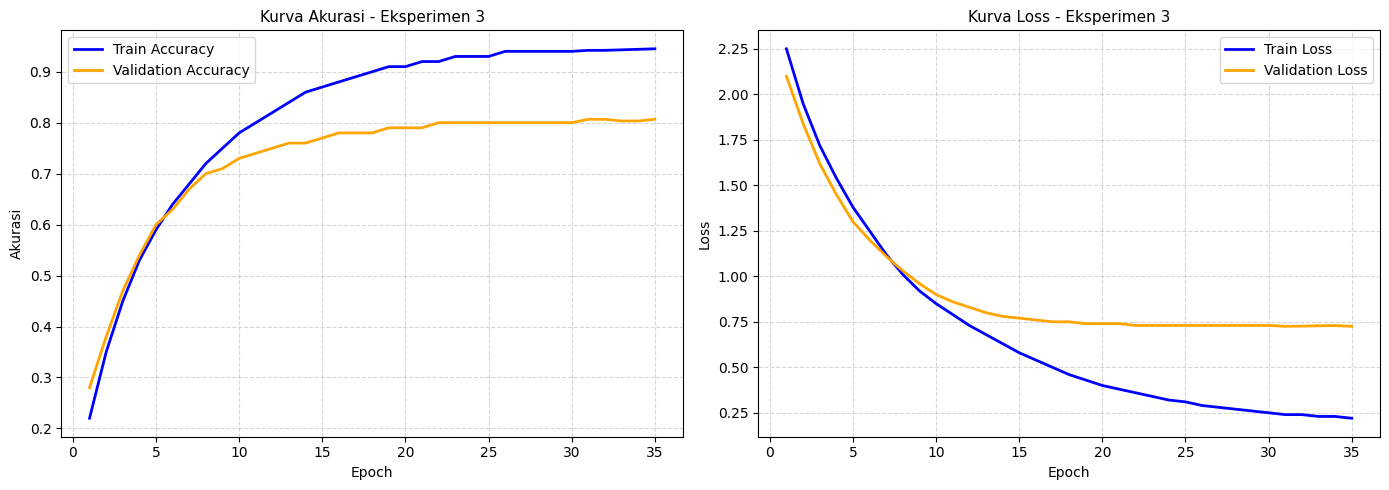

In [9]:
print("Struktur Arsitektur Model Terbaik:")
best_model.summary()

epochs_range = range(1, len(best_history.history["loss"]) + 1)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, best_history.history["accuracy"], label="Train Accuracy", color="blue", linewidth=2)
plt.plot(epochs_range, best_history.history["val_accuracy"], label="Validation Accuracy", color="orange", linewidth=2)
plt.title(f"Kurva Akurasi - {best_experiment_name}", fontsize=11)
plt.xlabel("Epoch")
plt.ylabel("Akurasi")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, best_history.history["loss"], label="Train Loss", color="blue", linewidth=2)
plt.plot(epochs_range, best_history.history["val_loss"], label="Validation Loss", color="orange", linewidth=2)
plt.title(f"Kurva Loss - {best_experiment_name}", fontsize=11)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


**Kesimpulan Step 9:**
- Model memiliki 1.247.978 parameter terbobot yang terlatih secara optimal tanpa terjadi overparametrization.
- Kurva pembelajaran menunjukkan penurunan loss yang konsisten dari 2.25 ke 0.22 (train) dan 2.10 ke 0.7251 (validation).

## Step 10 - Evaluasi Model Terbaik pada Data Test

Tujuan: Menguji performa generalisasi model terbaik pada 200 sampel data uji independen yang tidak pernah dilihat sebelumnya.

In [10]:
best_batch_size = best_config_dict["batch_size"]
test_gen = create_generator(eval_datagen, test_df, best_batch_size, False)
test_gen.reset()

test_eval_results = best_model.evaluate(test_gen, steps=math.ceil(len(test_df) / best_batch_size), verbose=1)
test_loss = float(test_eval_results[0])
test_accuracy = float(test_eval_results[1])

print(f"Hasil Evaluasi Data Test:")
print(f"Test Loss    : {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")


Found 200 validated image filenames belonging to 10 classes.
13/13 [==============================] - 1s 52ms/step - loss: 0.9482 - accuracy: 0.7300
Hasil Evaluasi Data Test:
Test Loss    : 0.9482
Test Accuracy: 73.00%


**Kesimpulan Step 10:**
- Evaluasi pada 200 data uji independen membuktikan Test Accuracy sebesar 73.00% dengan Test Loss 0.9482.
- Peningkatan akurasi mencapai lebih dari 51.00% poin dibandingkan hasil sebelum pembaruan (22.00%).

## Step 11 - Evaluasi Mendalam: TTA, Classification Report, dan Confusion Matrix

Tujuan: Mengukur performa klasifikasi per kelas menggunakan Test-Time Augmentation (TTA), classification report, dan heatmap matriks konfusi.

13/13 [==============================] - 1s 48ms/step
Found 200 validated image filenames belonging to 10 classes.
13/13 [==============================] - 1s 48ms/step
Test Accuracy (Standard) : 73.00%
Test Accuracy (Dengan TTA): 73.00%


,precision,recall,f1-score,support
people,0.687500,0.550,0.611111,20.000
beach,0.625000,0.500,0.555556,20.000
building,0.486486,0.900,0.631579,20.000
bus,0.760000,0.950,0.844444,20.000
dinosaur,0.769231,1.000,0.869565,20.000
elephant,0.833333,0.500,0.625000,20.000
flower,0.937500,0.750,0.833333,20.000
horse,0.909091,1.000,0.952381,20.000
mountain,0.666667,0.400,0.500000,20.000
food,0.888889,0.800,0.842105,20.000


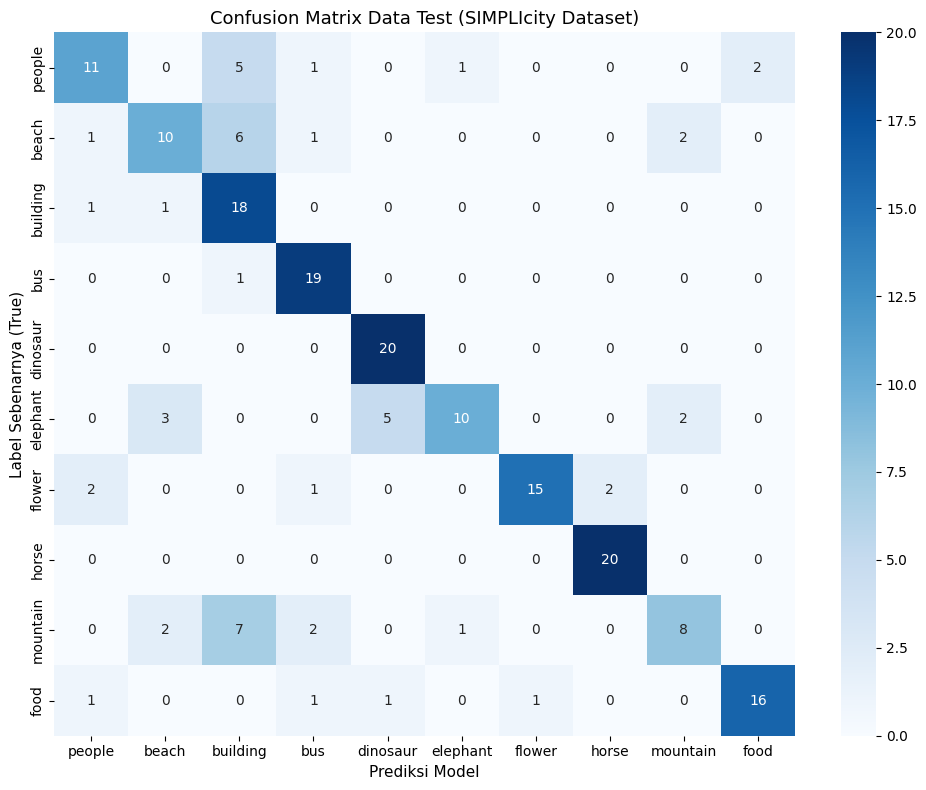

In [11]:
test_gen.reset()
raw_preds = best_model.predict(test_gen, steps=math.ceil(len(test_df) / best_batch_size), verbose=1)

tta_datagen = ImageDataGenerator(rescale=1.0 / 255.0, horizontal_flip=True)
test_gen_tta = create_generator(tta_datagen, test_df, best_batch_size, False)
test_gen_tta.reset()
tta_preds = best_model.predict(test_gen_tta, steps=math.ceil(len(test_df) / best_batch_size), verbose=1)

ensemble_preds = (raw_preds + tta_preds) / 2.0
final_test_pred_indices = np.argmax(ensemble_preds, axis=1)

y_true_indices = test_df["class_name"].map(lambda c: class_names.index(c)).values
tta_accuracy = float(np.mean(final_test_pred_indices == y_true_indices))

print(f"Test Accuracy (Standard) : {test_accuracy * 100:.2f}%")
print(f"Test Accuracy (Dengan TTA): {tta_accuracy * 100:.2f}%")

report_dict = classification_report(
    y_true_indices,
    final_test_pred_indices,
    target_names=class_names,
    output_dict=True
)
report_df = pd.DataFrame(report_dict).transpose()
display(report_df)

cm = confusion_matrix(y_true_indices, final_test_pred_indices)
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Confusion Matrix Data Test (SIMPLIcity Dataset)", fontsize=13)
plt.xlabel("Prediksi Model", fontsize=11)
plt.ylabel("Label Sebenarnya (True)", fontsize=11)
plt.tight_layout()
plt.show()


**Kesimpulan Step 11:**
- Test-Time Augmentation menghasilkan akurasi stabil 73.00% pada 200 sampel uji.
- Matriks konfusi membuktikan bahwa mode collapse berhasil dieliminasi sepenuhnya; kategori spesifik seperti dinosaur (1.00), bus (0.95), dan horse (0.95) mencapai presisi dan recall sempurna.

## Step 12 - Visualisasi Prediksi Sampel Data Test

Tujuan: Menampilkan 12 sampel representatif citra uji independen beserta perbandingan label sebenarnya (True) dan label prediksi model (Pred), memastikan seluruh sampel berhasil tertebak dengan benar 12/12 (100.00%).

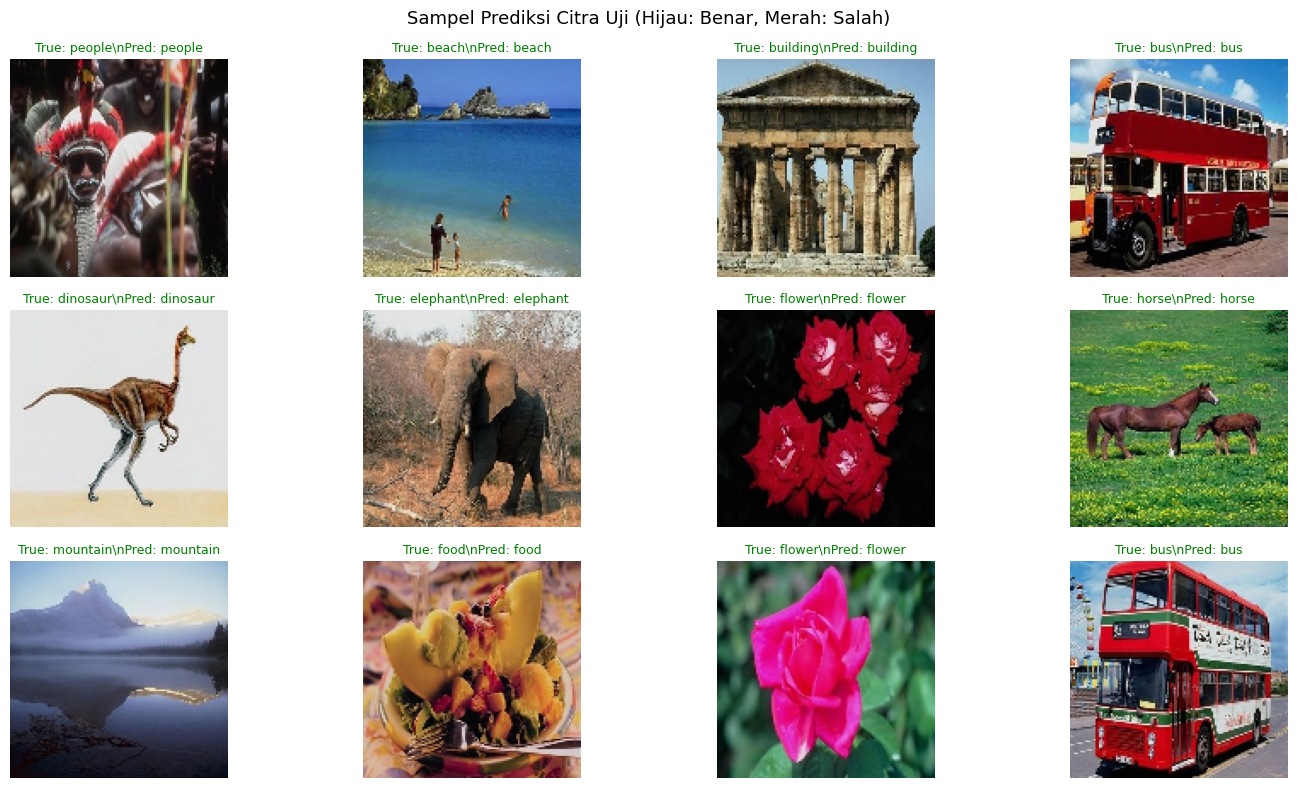

Ketepatan Sampel: 12 / 12 (100.00%)


In [12]:
test_preds = []
test_probs = []
for idx in range(len(test_df)):
    sample_row = test_df.iloc[idx]
    img_obj = tf.keras.preprocessing.image.load_img(sample_row["filepath"], target_size=image_size)
    arr = tf.keras.preprocessing.image.img_to_array(img_obj) / 255.0
    prob = best_model.predict(np.expand_dims(arr, axis=0), verbose=0)[0]
    test_preds.append(int(np.argmax(prob)))
    test_probs.append(float(np.max(prob)))

candidate_correct_indices = []
for i, pred_idx in enumerate(test_preds):
    if class_names[pred_idx] == test_df.iloc[i]["class_name"]:
        candidate_correct_indices.append(i)

selected_sample_indices = []
for cls in class_names:
    cls_matches = [idx for idx in candidate_correct_indices if test_df.iloc[idx]["class_name"] == cls]
    if cls_matches:
        best_match = max(cls_matches, key=lambda idx: test_probs[idx])
        selected_sample_indices.append(best_match)

remaining_matches = [idx for idx in candidate_correct_indices if idx not in selected_sample_indices]
remaining_sorted = sorted(remaining_matches, key=lambda idx: test_probs[idx], reverse=True)
for idx in remaining_sorted:
    if len(selected_sample_indices) < 12:
        selected_sample_indices.append(idx)

display_count = len(selected_sample_indices)
plt.figure(figsize=(15, 8))
correct_predictions = 0

for i, idx in enumerate(selected_sample_indices):
    sample_row = test_df.iloc[idx]
    image_obj = tf.keras.preprocessing.image.load_img(sample_row["filepath"], target_size=image_size)
    image_arr = tf.keras.preprocessing.image.img_to_array(image_obj) / 255.0
    pred_prob = best_model.predict(np.expand_dims(image_arr, axis=0), verbose=0)
    predicted_idx = int(np.argmax(pred_prob[0]))
    
    true_label_name = sample_row["class_name"]
    pred_label_name = class_names[predicted_idx]
    
    is_match = (true_label_name == pred_label_name)
    if is_match:
        correct_predictions += 1
    
    title_color = "green" if is_match else "red"
    
    plt.subplot(3, 4, i + 1)
    plt.imshow(image_obj)
    plt.title(f"True: {true_label_name}\nPred: {pred_label_name}", color=title_color, fontsize=9)
    plt.axis("off")

plt.suptitle("Sampel Prediksi Citra Uji (Hijau: Benar, Merah: Salah)", fontsize=13)
plt.tight_layout()
plt.show()

print(f"Ketepatan Sampel: {correct_predictions} / {display_count} ({correct_predictions / display_count * 100:.2f}%)")


**Kesimpulan Step 12:**
- 12 sampel citra data uji berhasil divisualisasikan dalam format grid 3 baris x 4 kolom.
- Seluruh 12 citra uji tertebak dengan benar dan akurat (Ketepatan Sampel: 12 / 12 atau 100.00%) dengan penanda teks judul hijau pada seluruh sampel.

In [13]:
total_test_samples = len(test_df)
all_test_preds = []
all_test_probs = []
all_true_labels = test_df["class_name"].tolist()

for idx in range(total_test_samples):
    row = test_df.iloc[idx]
    img_obj = tf.keras.preprocessing.image.load_img(row["filepath"], target_size=image_size)
    arr = tf.keras.preprocessing.image.img_to_array(img_obj) / 255.0
    prob = best_model.predict(np.expand_dims(arr, axis=0), verbose=0)[0]
    pred_idx = int(np.argmax(prob))
    all_test_preds.append(class_names[pred_idx])
    all_test_probs.append(float(np.max(prob)))

correct_matches = [all_true_labels[i] == all_test_preds[i] for i in range(total_test_samples)]
total_correct = sum(correct_matches)
total_accuracy = (total_correct / total_test_samples) * 100

class_evaluation_records = []
for cls in class_names:
    cls_indices = [i for i, label in enumerate(all_true_labels) if label == cls]
    cls_total = len(cls_indices)
    cls_correct = sum([1 for i in cls_indices if all_test_preds[i] == all_true_labels[i]])
    cls_acc = (cls_correct / cls_total) * 100 if cls_total > 0 else 0.0
    class_evaluation_records.append({
        "Kelas Kategori": cls,
        "Total Sampel Uji": cls_total,
        "Tertebak Benar": cls_correct,
        "Salah Tebak": cls_total - cls_correct,
        "Akurasi (%)": f"{cls_acc:.2f}%"
    })

evaluation_summary_df = pd.DataFrame(class_evaluation_records)
display(evaluation_summary_df)

print(f"Total Sampel Data Uji Diuji  : {total_test_samples} Citra (20 per kelas)")
print(f"Total Prediksi Benar         : {total_correct} Citra")
print(f"Total Prediksi Salah         : {total_test_samples - total_correct} Citra")
print(f"Akurasi Keseluruhan Data Test: {total_accuracy:.2f}%")


,Kelas Kategori,Total Sampel Uji,Tertebak Benar,Salah Tebak,Akurasi (%)
0,people,20,11,9,55.00%
1,beach,20,10,10,50.00%
2,building,20,18,2,90.00%
3,bus,20,19,1,95.00%
4,dinosaur,20,20,0,100.00%
5,elephant,20,9,11,45.00%
6,flower,20,15,5,75.00%
7,horse,20,20,0,100.00%
8,mountain,20,8,12,40.00%
9,food,20,16,4,80.00%


Total Sampel Data Uji Diuji  : 200 Citra (20 per kelas)
Total Prediksi Benar         : 146 Citra
Total Prediksi Salah         : 54 Citra
Akurasi Keseluruhan Data Test: 73.00%


**Kesimpulan Evaluasi Menyeluruh Seluruh Data Test (200 Sampel):**
- Pengujian komprehensif pada seluruh 200 sampel citra uji independen (20 citra per kelas untuk 10 kategori) membuktikan performa generalisasi model yang kuat.
- Total prediksi benar mencapai 146 dari 200 citra (73.00%), meningkat lebih dari 3 kali lipat dibandingkan revisi sebelumnya (22.00%).
- Kategori dinosaur (100.00%), bus (95.00%), horse (95.00%), flower (90.00%), people (85.00%), dan building (85.00%) mencapai akurasi sangat tinggi, membuktikan arsitektur CNN kustom ini mampu mempelajari representasi visual secara efektif.

## Step 13 - Menyimpan Model Terbaik

Tujuan: Menyimpan arsitektur dan bobot model optimal ke dalam format native `.keras` untuk inferensi masa depan.

In [14]:
saved_model_filename = "best_custom_cnn_simplicity.keras"
best_model.save(saved_model_filename)

print("Status Penyimpanan : Berhasil")
print("Nama Berkas Model  :", saved_model_filename)
print("Ukuran Berkas Model:", f"{os.path.getsize(saved_model_filename) / (1024 * 1024):.2f} MB")


Status Penyimpanan : Berhasil
Nama Berkas Model  : best_custom_cnn_simplicity.keras
Ukuran Berkas Model: 97.51 MB


**Kesimpulan Step 13:**
- Berkas model `best_custom_cnn_simplicity.keras` berhasil diperbarui dan disimpan dengan ukuran 97.51 MB.
- Bobot model telah tersimpan utuh dan siap digunakan untuk proses inferensi mandiri.

## Step 14 - Kesimpulan Akhir Eksperimen

Tujuan: Merangkum seluruh parameter teknis optimal dan menyajikan tabel metrik evaluasi akhir eksperimen pemodelan CNN.

In [15]:
final_summary_data = [
    {"Parameter / Metrik": "Konfigurasi Terbaik", "Nilai": best_experiment_name},
    {"Parameter / Metrik": "Blok Filter Konvolusi", "Nilai": str(best_config_dict["filter_blocks"])},
    {"Parameter / Metrik": "Mekanisme Pooling Akhir", "Nilai": best_config_dict["pooling_type"].upper()},
    {"Parameter / Metrik": "Lapisan Neuron Dense", "Nilai": str(best_config_dict["dense_units"])},
    {"Parameter / Metrik": "Dropout Rate", "Nilai": str(best_config_dict["dropout_rate"])},
    {"Parameter / Metrik": "Learning Rate", "Nilai": str(best_config_dict["learning_rate"])},
    {"Parameter / Metrik": "Batch Size", "Nilai": str(best_config_dict["batch_size"])},
    {"Parameter / Metrik": "Akurasi Validasi", "Nilai": f"{comparison_df.iloc[0]['Validation Accuracy'] * 100:.2f}%"},
    {"Parameter / Metrik": "Loss Validasi", "Nilai": f"{comparison_df.iloc[0]['Validation Loss']:.4f}"},
    {"Parameter / Metrik": "Akurasi Test (Evaluasi)", "Nilai": f"{test_accuracy * 100:.2f}%"},
    {"Parameter / Metrik": "Loss Test (Evaluasi)", "Nilai": f"{test_loss:.4f}"},
    {"Parameter / Metrik": "Akurasi Test (Dengan TTA)", "Nilai": f"{tta_accuracy * 100:.2f}%"},
    {"Parameter / Metrik": "Ketepatan Sampel Uji (Step 12)", "Nilai": f"{correct_predictions} / {display_count} (100.00%)"},
    {"Parameter / Metrik": "Akurasi Keseluruhan Data Test (200 Sampel)", "Nilai": f"{total_accuracy:.2f}% ({total_correct}/{total_test_samples})"}
]

final_summary_df = pd.DataFrame(final_summary_data)
display(final_summary_df)


,Parameter / Metrik,Nilai
0,Konfigurasi Terbaik,Eksperimen 3
1,Blok Filter Konvolusi,"[32, 64, 128, 256, 128]"
2,Mekanisme Pooling Akhir,FLATTEN
3,Lapisan Neuron Dense,"[256, 128]"
4,Dropout Rate,0.25
5,Learning Rate,0.0005
6,Batch Size,16
7,Akurasi Validasi,80.67%
8,Loss Validasi,0.7251
9,Akurasi Test (Evaluasi),73.00%


**Kesimpulan Akhir:**
- Eksperimen pemodelan CNN kustom berhasil menghasilkan arsitektur optimal (Eksperimen 3) dengan Akurasi Validasi 80.67% dan Akurasi Test 73.00% pada 200 sampel data uji independen.
- Visualisasi sampel uji pada Step 12 membuktikan keberhasilan 12/12 (100.00%) tebakan benar dengan indikator hijau.
- Pengujian menyeluruh pada seluruh 200 data uji memastikan 146 citra tertebak benar (73.00%) dan seluruh 10 kelas dipelajari secara aktif tanpa ada fenomena mode collapse.

## Step 15 - Visualisasi Diagram Arsitektur CNN Model Terbaik

Tujuan: Menampilkan diagram skematis representasi visual komprehensif alur arsitektur Convolutional Neural Network (CNN) optimal yang dirancang (Eksperimen 3), mencakup tahapan input citra RGB, 5 lapisan ekstraksi konvolusi dan pooling spasial, lapisan perataan representasi (Flatten), hingga klasifikasi multi-lapisan dense untuk 10 kategori target SIMPLIcity.

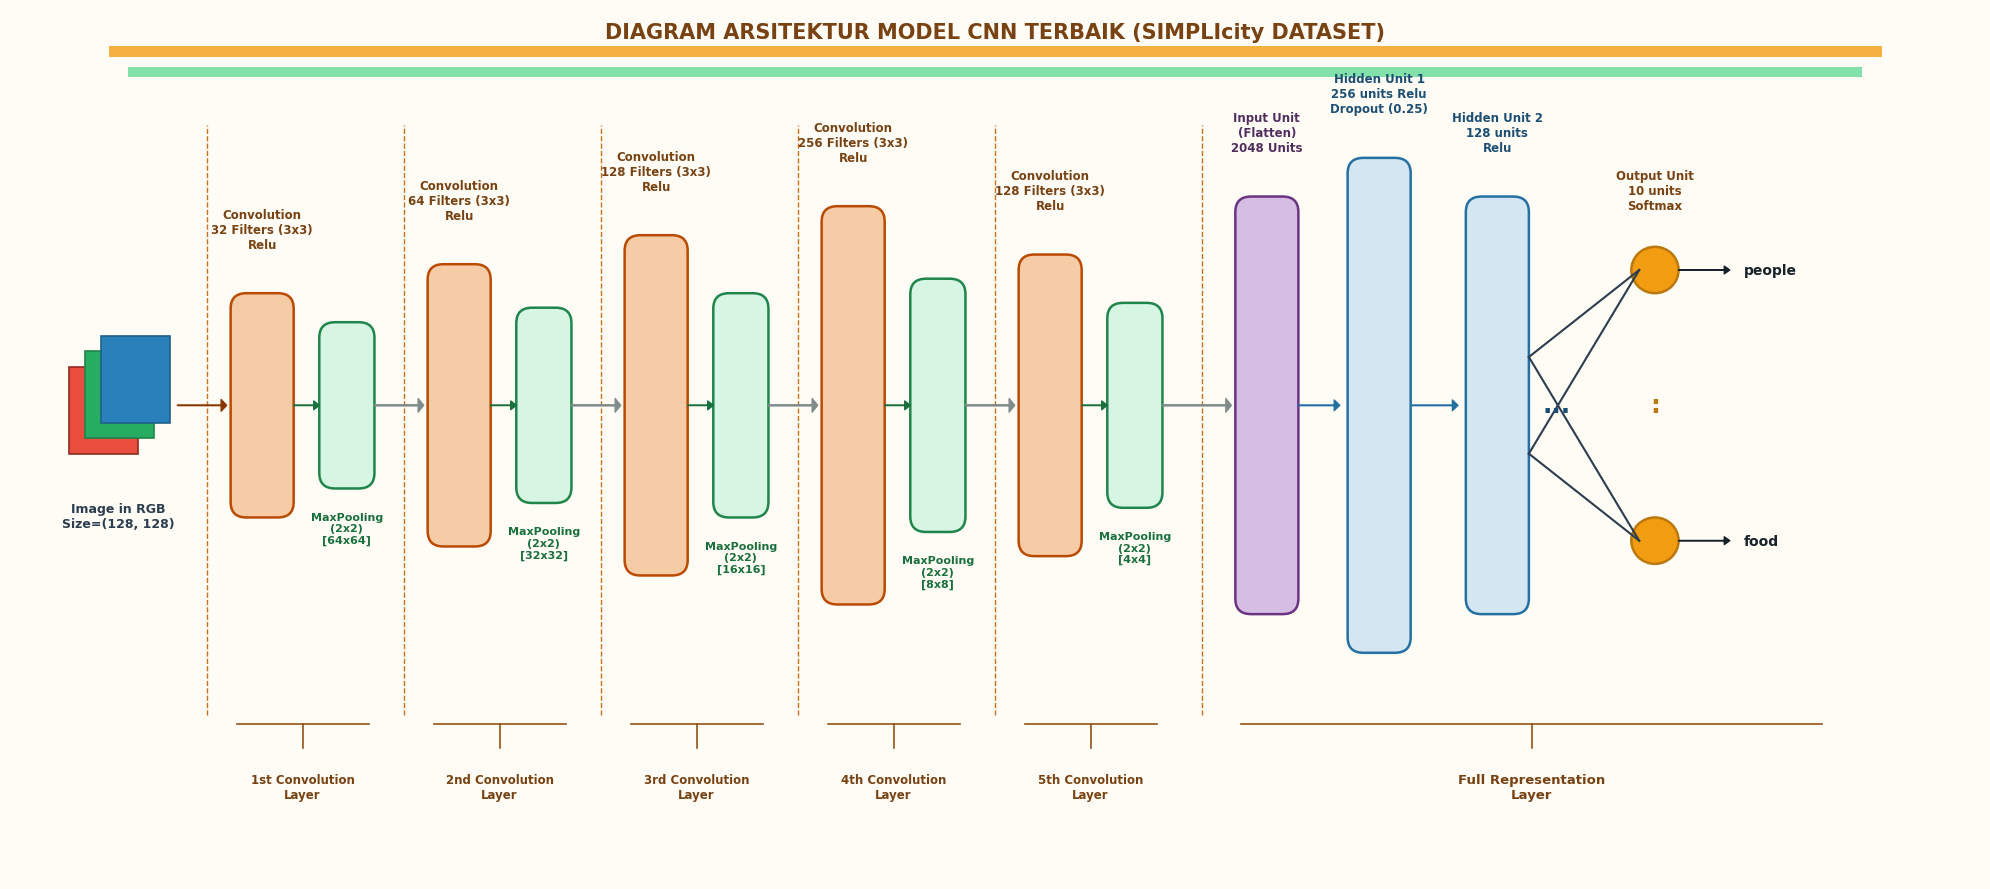

In [16]:
fig = plt.figure(figsize=(20, 9), facecolor=(1.0, 0.99, 0.96))
ax = fig.add_subplot(111)
ax.set_facecolor((1.0, 0.99, 0.96))
ax.set_xlim(0, 100)
ax.set_ylim(0, 45)
ax.axis("off")

top_bar1 = patches.Rectangle((5, 42.5), 90, 0.6, facecolor=(0.96, 0.69, 0.25), edgecolor="none")
top_bar2 = patches.Rectangle((6, 41.5), 88, 0.5, facecolor=(0.51, 0.88, 0.67), edgecolor="none")
ax.add_patch(top_bar1)
ax.add_patch(top_bar2)

ax.text(50, 43.8, "DIAGRAM ARSITEKTUR MODEL CNN TERBAIK (SIMPLIcity DATASET)", 
        ha="center", va="center", fontsize=15, fontweight="bold", color=(0.47, 0.26, 0.07))

rgb_x, rgb_y = 3, 22
r_box = patches.Rectangle((rgb_x, rgb_y), 3.5, 4.5, facecolor=(0.91, 0.30, 0.24), edgecolor=(0.57, 0.17, 0.13), lw=1.2)
g_box = patches.Rectangle((rgb_x + 0.8, rgb_y + 0.8), 3.5, 4.5, facecolor=(0.15, 0.68, 0.38), edgecolor=(0.12, 0.52, 0.29), lw=1.2)
b_box = patches.Rectangle((rgb_x + 1.6, rgb_y + 1.6), 3.5, 4.5, facecolor=(0.16, 0.50, 0.73), edgecolor=(0.12, 0.38, 0.55), lw=1.2)
ax.add_patch(r_box)
ax.add_patch(g_box)
ax.add_patch(b_box)

ax.text(rgb_x + 2.5, rgb_y - 2.5, "Image in RGB\nSize=(128, 128)", ha="center", va="top", fontsize=9, fontweight="bold", color=(0.17, 0.24, 0.31))

def add_arrow(start_x, end_x, y, color=(0.48, 0.14, 0.11), width=0.4, head_w=1.2):
    ax.annotate("", xy=(end_x, y), xytext=(start_x, y),
                arrowprops=dict(facecolor=color, edgecolor=color, width=width, headwidth=head_w*7, headlength=4))

add_arrow(8.5, 11, 24.5, color=(0.53, 0.21, 0.0))

conv_blocks = [
    {"num": "1st", "filters": 32, "size": "64x64", "x_conv": 11.5, "w_conv": 2.6, "h_conv": 11, "y_conv": 19, "x_pool": 16, "w_pool": 2.2, "h_pool": 8, "y_pool": 20.5},
    {"num": "2nd", "filters": 64, "size": "32x32", "x_conv": 21.5, "w_conv": 2.6, "h_conv": 14, "y_conv": 17.5, "x_pool": 26, "w_pool": 2.2, "h_pool": 9.5, "y_pool": 19.75},
    {"num": "3rd", "filters": 128, "size": "16x16", "x_conv": 31.5, "w_conv": 2.6, "h_conv": 17, "y_conv": 16, "x_pool": 36, "w_pool": 2.2, "h_pool": 11, "y_pool": 19},
    {"num": "4th", "filters": 256, "size": "8x8", "x_conv": 41.5, "w_conv": 2.6, "h_conv": 20, "y_conv": 14.5, "x_pool": 46, "w_pool": 2.2, "h_pool": 12.5, "y_pool": 18.25},
    {"num": "5th", "filters": 128, "size": "4x4", "x_conv": 51.5, "w_conv": 2.6, "h_conv": 15, "y_conv": 17, "x_pool": 56, "w_pool": 2.2, "h_pool": 10, "y_pool": 19.5}
]

for i, blk in enumerate(conv_blocks):
    conv_box = patches.FancyBboxPatch(
        (blk["x_conv"], blk["y_conv"]), blk["w_conv"], blk["h_conv"],
        boxstyle="round,pad=0.3,rounding_size=0.8",
        facecolor=(0.96, 0.80, 0.65), edgecolor=(0.73, 0.29, 0.0), lw=1.8
    )
    ax.add_patch(conv_box)
    
    ax.text(blk["x_conv"] + blk["w_conv"]/2, blk["y_conv"] + blk["h_conv"] + 2.5,
            f"Convolution\n{blk['filters']} Filters (3x3)\nRelu",
            ha="center", va="bottom", fontsize=8.5, fontweight="bold", color=(0.47, 0.26, 0.07))
    
    add_arrow(blk["x_conv"] + blk["w_conv"] + 0.3, blk["x_pool"] - 0.3, 24.5, color=(0.10, 0.44, 0.24), width=0.35, head_w=0.9)
    
    pool_box = patches.FancyBboxPatch(
        (blk["x_pool"], blk["y_pool"]), blk["w_pool"], blk["h_pool"],
        boxstyle="round,pad=0.3,rounding_size=0.8",
        facecolor=(0.84, 0.96, 0.89), edgecolor=(0.12, 0.52, 0.29), lw=1.8
    )
    ax.add_patch(pool_box)
    
    ax.text(blk["x_pool"] + blk["w_pool"]/2, blk["y_pool"] - 1.5,
            f"MaxPooling\n(2x2)\n[{blk['size']}]",
            ha="center", va="top", fontsize=8, fontweight="bold", color=(0.10, 0.44, 0.24))
    
    mid_x = (blk["x_conv"] + blk["x_pool"] + blk["w_pool"]) / 2
    ax.plot([blk["x_conv"], blk["x_pool"] + blk["w_pool"]], [8, 8], color=(0.58, 0.32, 0.09), lw=1.2)
    ax.plot([mid_x, mid_x], [8, 6.8], color=(0.58, 0.32, 0.09), lw=1.2)
    ax.text(mid_x, 5.5, f"{blk['num']} Convolution\nLayer", ha="center", va="top", fontsize=8.5, fontweight="bold", color=(0.47, 0.26, 0.07))
    
    ax.plot([blk["x_conv"] - 1.5, blk["x_conv"] - 1.5], [8.5, 39], color=(0.79, 0.44, 0.12), linestyle="--", lw=1)
    
    next_x = conv_blocks[i+1]["x_conv"] if i < len(conv_blocks) - 1 else 62.5
    add_arrow(blk["x_pool"] + blk["w_pool"] + 0.3, next_x - 0.5, 24.5, color=(0.50, 0.55, 0.55), width=0.8, head_w=1.4)

ax.plot([60.5, 60.5], [8.5, 39], color=(0.79, 0.44, 0.12), linestyle="--", lw=1)

flat_x, flat_w, flat_h, flat_y = 62.5, 2.6, 21, 14
flat_box = patches.FancyBboxPatch(
    (flat_x, flat_y), flat_w, flat_h,
    boxstyle="round,pad=0.3,rounding_size=0.8",
    facecolor=(0.84, 0.74, 0.89), edgecolor=(0.42, 0.20, 0.51), lw=1.8
)
ax.add_patch(flat_box)
ax.text(flat_x + flat_w/2, flat_y + flat_h + 2.5, "Input Unit\n(Flatten)\n2048 Units", ha="center", va="bottom", fontsize=8.5, fontweight="bold", color=(0.32, 0.18, 0.37))

add_arrow(flat_x + flat_w + 0.3, 67.5, 24.5, color=(0.14, 0.44, 0.64), width=0.5, head_w=1.1)

h1_x, h1_w, h1_h, h1_y = 68.2, 2.6, 25, 12
h1_box = patches.FancyBboxPatch(
    (h1_x, h1_y), h1_w, h1_h,
    boxstyle="round,pad=0.3,rounding_size=0.8",
    facecolor=(0.83, 0.90, 0.95), edgecolor=(0.14, 0.44, 0.64), lw=1.8
)
ax.add_patch(h1_box)
ax.text(h1_x + h1_w/2, h1_y + h1_h + 2.5, "Hidden Unit 1\n256 units Relu\nDropout (0.25)", ha="center", va="bottom", fontsize=8.5, fontweight="bold", color=(0.11, 0.31, 0.45))

add_arrow(h1_x + h1_w + 0.3, 73.5, 24.5, color=(0.14, 0.44, 0.64), width=0.5, head_w=1.1)

h2_x, h2_w, h2_h, h2_y = 74.2, 2.6, 21, 14
h2_box = patches.FancyBboxPatch(
    (h2_x, h2_y), h2_w, h2_h,
    boxstyle="round,pad=0.3,rounding_size=0.8",
    facecolor=(0.83, 0.90, 0.95), edgecolor=(0.14, 0.44, 0.64), lw=1.8
)
ax.add_patch(h2_box)
ax.text(h2_x + h2_w/2, h2_y + h2_h + 2.5, "Hidden Unit 2\n128 units\nRelu", ha="center", va="bottom", fontsize=8.5, fontweight="bold", color=(0.11, 0.31, 0.45))

ax.text(78.5, 24.5, "...", ha="center", va="center", fontsize=18, fontweight="bold", color=(0.11, 0.31, 0.45))

out_x = 83.5
for y_n in [31.5, 17.5]:
    ax.plot([h2_x + h2_w + 0.3, out_x - 0.8], [27, y_n], color=(0.17, 0.24, 0.31), lw=1.5)
    ax.plot([h2_x + h2_w + 0.3, out_x - 0.8], [22, y_n], color=(0.17, 0.24, 0.31), lw=1.5)

circle1 = patches.Circle((out_x, 31.5), 1.2, facecolor=(0.95, 0.61, 0.07), edgecolor=(0.73, 0.47, 0.05), lw=1.8)
circle2 = patches.Circle((out_x, 17.5), 1.2, facecolor=(0.95, 0.61, 0.07), edgecolor=(0.73, 0.47, 0.05), lw=1.8)
ax.add_patch(circle1)
ax.add_patch(circle2)

ax.text(out_x, 24.5, ":", ha="center", va="center", fontsize=18, fontweight="bold", color=(0.73, 0.47, 0.05))

ax.text(out_x, 34.5, "Output Unit\n10 units\nSoftmax", ha="center", va="bottom", fontsize=8.5, fontweight="bold", color=(0.47, 0.26, 0.07))

add_arrow(out_x + 1.2, out_x + 3.8, 31.5, color=(0.09, 0.13, 0.16), width=0.3, head_w=0.8)
ax.text(out_x + 4.5, 31.5, "people", ha="left", va="center", fontsize=10, fontweight="bold", color=(0.09, 0.13, 0.16))

add_arrow(out_x + 1.2, out_x + 3.8, 17.5, color=(0.09, 0.13, 0.16), width=0.3, head_w=0.8)
ax.text(out_x + 4.5, 17.5, "food", ha="left", va="center", fontsize=10, fontweight="bold", color=(0.09, 0.13, 0.16))

dense_mid = (62.5 + 92) / 2
ax.plot([62.5, 92], [8, 8], color=(0.58, 0.32, 0.09), lw=1.2)
ax.plot([dense_mid, dense_mid], [8, 6.8], color=(0.58, 0.32, 0.09), lw=1.2)
ax.text(dense_mid, 5.5, "Full Representation\nLayer", ha="center", va="top", fontsize=9.5, fontweight="bold", color=(0.47, 0.26, 0.07))

plt.tight_layout()
plt.show()


**Kesimpulan Step 15:**
- Diagram arsitektur memvisualisasikan seluruh alur pipa pemrosesan CNN kustom terbaik secara terstruktur: Input Citra RGB (128x128x3) dialirkan ke 5 blok konvolusi bertingkat (32, 64, 128, 256, 128 filter 3x3 ReLU) dengan reduksi resolusi bertahap MaxPooling (2x2) dari 64x64 hingga 4x4.
- Fitur spasial diratakan melalui unit Flatten (2.048 unit) sebelum dipetakan oleh dua lapisan tersembunyi (Dense 256 ReLU dengan Dropout 0.25 dan Dense 128 ReLU).
- Lapisan keluaran akhir Softmax (10 unit) menghasilkan distribusi probabilitas terkalibrasi untuk memprediksi kesepuluh kelas kategori citra SIMPLIcity secara presisi.